# Project 2 — Text-to-Image Generation
## Milestone 2: Conditional Generation & Parameter Sweeps

**IE 7615** — Project 2, Milestone 2

**David Fung**

This notebook uses the text-conditional DDPM trained in `Integration_Training.ipynb` to
demonstrate the full prompt → embedding → conditioning → image pathway, then experiments
with **classifier-free guidance scale**, **number of sampling steps**, **noise schedule**
(linear vs cosine), and **sampler choice** (DDPM vs DDIM). It produces a baseline
prompt→image gallery with ground-truth comparisons, records seeds/parameters/timing, and
writes a qualitative analysis memo. It reuses the dataset, CLIP pipeline, model
architecture and diffusion process established in Milestone 1 / the training notebook.


In [1]:
import os
import time
import json
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from transformers import CLIPProcessor, CLIPModel

print(f"PyTorch:    {torch.__version__}")
print(f"CUDA:       {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU:        {torch.cuda.get_device_name(0)}")


PyTorch:    2.12.0+cu130
CUDA:       True
GPU:        NVIDIA GB10


In [2]:
# PROJECT CONSTANTS

GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(GLOBAL_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# SMOKE_TEST = True for a fast end-to-end sanity run (fewer prompts/sweeps).
SMOKE_TEST = False

# Paths (relative to this notebook, Milestone_2/)
DATA_DIR        = "../data"
CURATED_DIR     = os.path.join(DATA_DIR, "curated")
MANIFEST_PATH   = os.path.join(CURATED_DIR, "manifest.csv")
OUTPUT_DIR      = "outputs"
GALLERY_DIR     = "gallery"
baseline_dir    = "gallery/baseline"
os.makedirs(os.path.join(GALLERY_DIR, "baseline"), exist_ok=True)
os.makedirs(os.path.join(GALLERY_DIR, "guidance"), exist_ok=True)
os.makedirs(os.path.join(GALLERY_DIR, "sampling"), exist_ok=True)
CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "ddpm_text_conditional.pt")

# Models
CLIP_MODEL_NAME = "openai/clip-vit-base-patch32"

# Generation settings
#MG_SIZE        = 512
NUM_PROMPTS     = 16 if not SMOKE_TEST else 4
BASE_GUIDANCE   = 10
BASE_STEPS      = 50
SWEEP_PROMPTS   = 3                          # prompts used in sweeps (bounds runtime)
GUIDANCE_SWEEP  = [1.0, 3.0, 7.5, 10.0, 15.0]      # >= 3 classifier-free guidance settings
STEPS_SWEEP     = [25, 50, 100]              # number of sampling steps (DDIM)
SCHEDULE_SWEEP  = ["linear", "cosine"]       # noise schedule
SAMPLER_SWEEP   = ["ddim", "ddpm"]           # sampler choice

print(f"Device:           {DEVICE}")
print(f"Smoke test:       {SMOKE_TEST}")
print(f"Baseline:         {NUM_PROMPTS} prompts @ guidance={BASE_GUIDANCE}, steps={BASE_STEPS}")
print(f"Guidance sweep:   {GUIDANCE_SWEEP}")
print(f"Steps sweep:      {STEPS_SWEEP}")
print(f"Schedule sweep:   {SCHEDULE_SWEEP}")
print(f"Sampler sweep:    {SAMPLER_SWEEP}")


Device:           cuda
Smoke test:       False
Baseline:         16 prompts @ guidance=10, steps=50
Guidance sweep:   [1.0, 3.0, 7.5, 10.0, 15.0]
Steps sweep:      [25, 50, 100]
Schedule sweep:   ['linear', 'cosine']
Sampler sweep:    ['ddim', 'ddpm']


In [3]:
def cosine_beta_schedule(T, s=0.008):
    steps = T + 1
    t = torch.linspace(0, 1, steps, dtype=torch.float64)
    alphas_cumprod = torch.cos((t + s) / (1 + s) * math.pi * 0.5) ** 2
    betas = 1 - (alphas_cumprod[1:] / alphas_cumprod[:-1])
    return torch.clip(betas, 0.0001, 0.9999).float()

def linear_beta_schedule(T):
    return torch.linspace(0.0001, 0.02, T).float()

class GaussianDiffusion:
    """Epsilon-prediction DDPM with cosine/linear schedules, DDIM + DDPM samplers, CFG."""
    def __init__(self, T, schedule="cosine", device="cpu"):
        self.T = T
        self.device = device
        self.schedule = schedule
        self.betas = (cosine_beta_schedule(T) if schedule == "cosine"
                      else linear_beta_schedule(T)).to(device)
        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=0)
        self.alphas_cumprod_prev = F.pad(self.alphas_cumprod[:-1], (1, 0))
        self.sqrt_alphas_cumprod = self.alphas_cumprod.sqrt()
        self.sqrt_one_minus_alphas_cumprod = (1.0 - self.alphas_cumprod).sqrt()
        self.posterior_mean_coef1 = self.betas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)
        self.posterior_mean_coef2 = self.alphas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)
        self.posterior_var = self.betas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)

    def _cfg_eps(self, model, x, t, text_emb, guidance_scale):
        t_batch = torch.tensor([t], device=x.device, dtype=torch.long)
        null = model.null_text
        if null.dim() == 1:
            null = null.unsqueeze(0)
        eps_cond   = model(x, t_batch, text_emb)
        eps_uncond = model(x, t_batch, null)
        return eps_uncond + guidance_scale * (eps_cond - eps_uncond)

    def ddim_prev(self, xt, t, eps, a_prev, eta=0.0):
        a_t = self.alphas_cumprod[t]
        x0_pred = (xt - self.sqrt_one_minus_alphas_cumprod[t] * eps) / self.sqrt_alphas_cumprod[t]
        x0_pred = torch.clamp(x0_pred, -1.0, 1.0)
        sigma = eta * ((1.0 - a_prev) / (1.0 - a_t)).sqrt() * (1.0 - a_t / a_prev).sqrt()
        dir_xt = (1.0 - a_prev - sigma ** 2).clamp(min=0.0).sqrt() * eps
        x_prev = a_prev.sqrt() * x0_pred + dir_xt
        if eta > 0:
            x_prev = x_prev + sigma * torch.randn_like(xt)
        return x_prev

    def sample_ddim(self, model, text_emb, guidance_scale, n_steps, seed=42, eta=0.0,
                    device="cpu", img_size=32, channels=3):
        model.eval()
        gen = torch.Generator().manual_seed(seed)
        step = max(1, self.T // n_steps)
        timesteps = list(range(self.T - step, -1, -step))
        x = torch.randn(1, channels, img_size, img_size, generator=gen).to(device)
        with torch.no_grad():
            for i, t in enumerate(timesteps):
                eps = self._cfg_eps(model, x, t, text_emb, guidance_scale)
                t_prev = timesteps[i + 1] if (i + 1) < len(timesteps) else 0
                x = self.ddim_prev(x, t, eps, self.alphas_cumprod[t_prev], eta)
        return torch.clamp(x, -1.0, 1.0)

    def sample_ddpm(self, model, text_emb, guidance_scale, seed=42,
                    device="cpu", img_size=32, channels=3):
        """Standard (stochastic) DDPM reverse process over all T steps."""
        model.eval()
        gen = torch.Generator().manual_seed(seed)
        x = torch.randn(1, channels, img_size, img_size, generator=gen).to(device)
        with torch.no_grad():
            for t in reversed(range(1, self.T)):
                eps = self._cfg_eps(model, x, t, text_emb, guidance_scale)
                x0_pred = (x - self.sqrt_one_minus_alphas_cumprod[t] * eps) / self.sqrt_alphas_cumprod[t]
                mean = (self.posterior_mean_coef1[t] * x0_pred
                        + self.posterior_mean_coef2[t] * x)
                noise = torch.randn(1, channels, img_size, img_size, generator=gen).to(device)
                x = mean + self.posterior_var[t].sqrt() * noise
                x = torch.clamp(x, -1.0, 1.0)    
        return torch.clamp(x, -1.0, 1.0)


In [4]:
def sinusoidal_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device).float() / half)
    args = t[:, None].float() * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

class TimestepEmbed(nn.Module):
    def __init__(self, sin_dim=256, cond_dim=256):
        super().__init__()
        self.sin_dim = sin_dim
        self.mlp = nn.Sequential(nn.Linear(sin_dim, sin_dim * 4), nn.GELU(),
                                 nn.Linear(sin_dim * 4, cond_dim))
    def forward(self, t):
        return self.mlp(sinusoidal_embedding(t, self.sin_dim))

class AdaGNBlock(nn.Module):
    def __init__(self, in_c, out_c, cond_dim, groups=8):
        super().__init__()
        self.norm1 = nn.GroupNorm(groups, in_c)
        self.conv1 = nn.Conv2d(in_c, out_c, 3, padding=1)
        self.norm2 = nn.GroupNorm(groups, out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, padding=1)
        self.adapt1 = nn.Sequential(nn.SiLU(), nn.Linear(cond_dim, 2 * in_c))
        self.adapt2 = nn.Sequential(nn.SiLU(), nn.Linear(cond_dim, 2 * out_c))
        self.skip = nn.Conv2d(in_c, out_c, 1) if in_c != out_c else nn.Identity()
    def _modulate(self, x, norm, adapt, cond):
        gamma, beta = adapt(cond).chunk(2, dim=-1)
        return gamma[..., None, None] * norm(x) + beta[..., None, None]
    def forward(self, x, cond):
        h = F.silu(self._modulate(x, self.norm1, self.adapt1, cond))
        h = self.conv1(h)
        h = F.silu(self._modulate(h, self.norm2, self.adapt2, cond))
        h = self.conv2(h)
        return h + self.skip(x)

class DownBlock(nn.Module):
    def __init__(self, in_c, out_c, cond_dim):
        super().__init__()
        self.res1 = AdaGNBlock(in_c, out_c, cond_dim)
        self.res2 = AdaGNBlock(out_c, out_c, cond_dim)
        self.down = nn.Conv2d(out_c, out_c, 3, stride=2, padding=1)
    def forward(self, x, cond):
        h = self.res1(x, cond); h = self.res2(h, cond)
        return self.down(h)

class UpBlock(nn.Module):
    def __init__(self, in_c, skip_c, out_c, cond_dim):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2)
        self.res1 = AdaGNBlock(in_c + skip_c, out_c, cond_dim)
        self.res2 = AdaGNBlock(out_c, out_c, cond_dim)
    def forward(self, x, skip, cond):
        h = torch.cat([self.up(x), skip], dim=1)
        return self.res2(self.res1(h, cond), cond)

class TextConditionedUNet(nn.Module):
    def __init__(self, in_channels=3, base=64, cond_dim=256, text_dim=512):
        super().__init__()
        self.time_embed = TimestepEmbed(256, cond_dim)
        self.text_embed = nn.Sequential(nn.Linear(text_dim, cond_dim), nn.GELU())
        self.null_text  = nn.Parameter(torch.randn(text_dim) * 0.02)
        c = [base, base * 2, base * 4, base * 8]
        self.input_conv = nn.Conv2d(in_channels, base, 3, padding=1)
        self.downs = nn.ModuleList([DownBlock(c[i], c[i + 1], cond_dim) for i in range(3)])
        self.mid1 = AdaGNBlock(c[3], c[3], cond_dim)
        self.mid2 = AdaGNBlock(c[3], c[3], cond_dim)
        self.ups = nn.ModuleList([UpBlock(c[i + 1], c[i + 1], c[i], cond_dim)
                                  for i in range(2, -1, -1)])
        self.out_norm = nn.GroupNorm(8, base)
        self.out_conv = nn.Conv2d(base, in_channels, 3, padding=1)
    def forward(self, x, t, text_emb):
        cond = self.time_embed(t) + self.text_embed(text_emb)
        h = self.input_conv(x)
        skips = [h]
        for d in self.downs:
            h_res = d.res1(h, cond)
            h_res = d.res2(h_res, cond)
            skips.append(h_res)
            h = d.down(h_res)
        h = F.silu(self.mid1(h, cond)); h = self.mid2(h, cond)
        for u in self.ups:
            h = u(h, skips.pop(), cond)
        return self.out_conv(F.silu(self.out_norm(h)))


In [5]:
ckpt = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
cfg = ckpt["config"]
print("Checkpoint config:", cfg)
print(f"Best val loss:    {ckpt['best_val_loss']:.5f}")
print(f"Epochs trained:   {len(ckpt['history']['train_loss'])}")

model = TextConditionedUNet(cfg["IN_CHANNELS"], cfg["BASE_CHANNELS"],
                            cfg["COND_DIM"], cfg["CLIP_TEXT_DIM"])
model.load_state_dict(ckpt["ema_state"])          # use EMA weights for generation
model.to(DEVICE).eval()
n_params = sum(p.numel() for p in model.parameters())
print(f"Loaded model: {n_params/1e6:.2f}M parameters (EMA weights)")

IMG_SIZE      = cfg["IMG_SIZE"]
IN_CHANNELS   = cfg["IN_CHANNELS"]
N_TIMESTEPS   = cfg["N_TIMESTEPS"]
BETA_SCHEDULE = cfg["BETA_SCHEDULE"]

# Diffusion objects for both schedules (used by the sampling sweeps)
diff_by_schedule = {
    s: GaussianDiffusion(N_TIMESTEPS, s, DEVICE) for s in SCHEDULE_SWEEP
}
diff = diff_by_schedule[BETA_SCHEDULE if BETA_SCHEDULE in diff_by_schedule else "cosine"]
print("Diffusion schedules ready:", list(diff_by_schedule.keys()))


Checkpoint config: {'IMG_SIZE': 64, 'BASE_CHANNELS': 64, 'COND_DIM': 256, 'CLIP_TEXT_DIM': 512, 'N_TIMESTEPS': 1000, 'BETA_SCHEDULE': 'cosine', 'IN_CHANNELS': 3}
Best val loss:    0.03810
Epochs trained:   500
Loaded model: 34.27M parameters (EMA weights)
Diffusion schedules ready: ['linear', 'cosine']


## Task 1 — Baseline Conditional Generation

Select a fixed, evenly-spaced set of `16` prompts from the curated dataset, encode each
with the frozen CLIP text encoder, and generate a 32×32 image with the text-conditional
DDPM at the baseline setting (guidance `7.5`, `50` DDIM steps, seed 42). Each output is
saved with its prompt, seed and parameters and shown next to its ground-truth Flickr image.

**Why this proves conditioning (not just "can make an image"):** the *same* model and seed
produces different images for different prompts — we verify this in Task 3 by re-running a
prompt with the unconditional (null) embedding, which should ignore the text.


In [6]:
def clean_caption(text):
    return ' '.join(str(text).strip().lower().split())

df_manifest = pd.read_csv(MANIFEST_PATH).drop_duplicates(subset=['image_id']).reset_index(drop=True)
df_manifest['caption'] = df_manifest['caption'].apply(clean_caption)

# Fixed, evenly-spaced baseline prompts
prompt_idx = np.linspace(0, len(df_manifest) - 1, NUM_PROMPTS, dtype=int)
prompts_df = df_manifest.iloc[prompt_idx].reset_index(drop=True)
print(f"Selected {len(prompts_df)} baseline prompts:")
for i, row in prompts_df.iterrows():
    print(f"  [{i:2d}] (id={row['image_id']}) {row['caption']}")

# Encode prompts with frozen CLIP
clip_model = CLIPModel.from_pretrained(CLIP_MODEL_NAME).to(DEVICE) 
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_NAME)
clip_model.eval()
def encode_captions(texts, batch_size=64):
    out = []
    for i in range(0, len(texts), batch_size):
        inputs = clip_processor(text=texts[i:i+batch_size], return_tensors="pt",
                                padding=True, truncation=True, max_length=77).to(DEVICE)
        with torch.no_grad():
            e = clip_model.get_text_features(**inputs)
            if not isinstance(e, torch.Tensor):
                e = e.pooler_output
            e = torch.nn.functional.normalize(e, dim=-1)
        out.append(e.cpu().numpy())
    return np.concatenate(out, axis=0).astype(np.float32)

prompt_embeddings = encode_captions(prompts_df['caption'].tolist())
print(f"Prompt embeddings: {prompt_embeddings.shape}")
del clip_model, clip_processor
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Ground-truth images for comparison
gt_images = [Image.open(os.path.join(CURATED_DIR, str(i))).convert("RGB")
             for i in prompts_df['image_id']]

def tensor_to_pil(x):
    x = (x + 1) / 2
    x = x.clamp(0, 1).squeeze(0).permute(1, 2, 0).cpu().numpy()
    x = np.nan_to_num(x)
    return Image.fromarray((x * 255).astype('uint8'))

def generate_one(prompt_i, guidance, steps=50, schedule="cosine", sampler="ddim", seed=42):
    """Generate one image; returns (PIL image, elapsed_seconds)."""
    emb = torch.from_numpy(prompt_embeddings[prompt_i]).unsqueeze(0).to(DEVICE)   # (1, 512)
    d = diff_by_schedule[schedule]
    t0 = time.time()
    with torch.no_grad():
        if sampler == "ddim":
            x = d.sample_ddim(model, emb, guidance, steps, seed=seed, device=DEVICE,
                              img_size=IMG_SIZE, channels=IN_CHANNELS)
        else:
            x = d.sample_ddpm(model, emb, guidance, seed=seed, device=DEVICE,
                              img_size=IMG_SIZE, channels=IN_CHANNELS)
    return tensor_to_pil(x), time.time() - t0


Selected 16 baseline prompts:
  [ 0] (id=0) two young guys with shaggy hair look at their hands while hanging out in the yard.
  [ 1] (id=367) a man wearing a yellow shirt and tan pants plays golf outside while being watched by other people.
  [ 2] (id=729) three people wearing colorful costumes and masks sitting between two stone statues.
  [ 3] (id=1085) a man in jeans and a white t-shirt chops up vegetables in a kitchen.
  [ 4] (id=1452) a man with a white shirt and rubber boots is climbing on tanks in order to retrieve items from a specific tank.
  [ 5] (id=1807) the girl is wearing a white shirt with pink skirt, and she is standing in front of a house.
  [ 6] (id=2166) a young man, in a baseball cap and blue striped shirt, is playing the guitar.
  [ 7] (id=2524) a woman in a red hat sits on a winding purple and bright green bench with a bush in the background.
  [ 8] (id=2873) a boy in blue and red goggles is swimming.
  [ 9] (id=3231) a girl in a purple dress smiling as she climb

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Prompt embeddings: (16, 512)


In [7]:
#baseline_dir = os.path.join(GALLERY_DIR, "baseline")
manifest = []          # accumulates every generation for the final manifest
baseline_times = []
for i in range(len(prompts_df)):
    img, t = generate_one(i, BASE_GUIDANCE, BASE_STEPS, schedule="cosine",
                          sampler="ddim", seed=GLOBAL_SEED + i)
    fname = f"base_{i:02d}.png"
    img.save(os.path.join(baseline_dir, fname))
    baseline_times.append(t)
    manifest.append({
        "task": "baseline", "index": i,
        "prompt": prompts_df.iloc[i]["caption"], "gt_image_id": prompts_df.iloc[i]["image_id"],
        "seed": GLOBAL_SEED + i, "guidance": BASE_GUIDANCE, "steps": BASE_STEPS,
        "schedule": "cosine", "sampler": "ddim", "time_s": round(t, 2), "file": fname,
    })
    print(f"[{i:2d}/{len(prompts_df)}] {t:.1f}s   {prompts_df.iloc[i]['caption'][:48]}")

print(f"\nBaseline: {len(prompts_df)} images in {sum(baseline_times):.1f}s "
      f"(mean {np.mean(baseline_times):.1f}s/image)")


[ 0/16] 0.6s   two young guys with shaggy hair look at their ha
[ 1/16] 0.5s   a man wearing a yellow shirt and tan pants plays
[ 2/16] 0.5s   three people wearing colorful costumes and masks
[ 3/16] 0.5s   a man in jeans and a white t-shirt chops up vege
[ 4/16] 0.5s   a man with a white shirt and rubber boots is cli
[ 5/16] 0.5s   the girl is wearing a white shirt with pink skir
[ 6/16] 0.5s   a young man, in a baseball cap and blue striped 
[ 7/16] 0.5s   a woman in a red hat sits on a winding purple an
[ 8/16] 0.5s   a boy in blue and red goggles is swimming.
[ 9/16] 0.5s   a girl in a purple dress smiling as she climbs a
[10/16] 0.5s   the little boy with the yellow stripe on his hat
[11/16] 0.5s   a black dog is attempting to catch a thrown obje
[12/16] 0.5s   a crowded stadium is full of people watching an 
[13/16] 0.5s   a fluffy dog plays with a small toy in a living 
[14/16] 0.5s   a man in a yellow reflective vest squats on a la
[15/16] 0.5s   a man is standing inside a buil

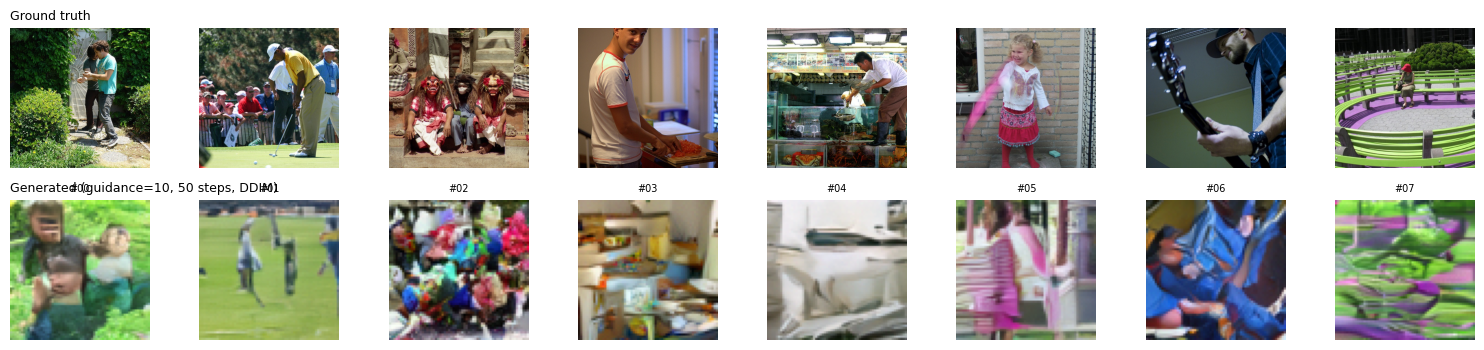

Saved baseline comparison grid -> gallery/baseline/baseline_comparison.png


In [8]:
def show_grid(images, captions, col_titles=None, ncols=None, figsize=(1.9, 3.2)):
    rows = math.ceil(len(images) / (ncols or 4))
    fig, axes = plt.subplots(rows, ncols or 4, figsize=(figsize[0] * (ncols or 4), figsize[1] * rows))
    axes = np.atleast_1d(axes).reshape(-1)
    for ax, im, cap in zip(axes, images, captions):
        ax.imshow(im); ax.axis('off'); ax.set_title(cap, fontsize=7)
    for ax in axes[len(images):]:
        ax.axis('off')
    plt.tight_layout()
    return fig

# Baseline: ground truth (top row) vs generated (bottom row), 8 per row
n = len(gt_images)
gen_imgs = [Image.open(os.path.join(baseline_dir, f"base_{i:02d}.png")) for i in range(n)]
ncols = 8
fig, axes = plt.subplots(2, ncols, figsize=(1.9 * ncols, 3.6))
for j in range(ncols):
    axes[0, j].axis('off'); axes[1, j].axis('off')
    if j < n:
        axes[0, j].imshow(gt_images[j])
        axes[1, j].imshow(gen_imgs[j])
        axes[1, j].set_title(f"#{j:02d}", fontsize=7)
axes[0, 0].set_title("Ground truth", loc='left', fontsize=9)
axes[1, 0].set_title(f"Generated (guidance={BASE_GUIDANCE}, {BASE_STEPS} steps, DDIM)",
                     loc='left', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(baseline_dir, "baseline_comparison.png"), dpi=120, bbox_inches='tight')
plt.show()
print(f"Saved baseline comparison grid -> {os.path.join(baseline_dir, 'baseline_comparison.png')}")


## Task 2 — Guidance-Scale Sweep

Sweep classifier-free guidance `s` across **4 settings** (`1.0, 3.0, 7.5, 15.0`) on the same
`3` prompts. Higher guidance pulls the denoising toward the prompt (sharper alignment) but
over-saturates colour and reduces diversity. For each setting we save the images, record the
timing, and (in the metrics cell below) compute an objective **CLIP text–image alignment**
score and a **diversity** score across the outputs.


In [9]:
sweep_idx = list(range(SWEEP_PROMPTS))            # first SWEEP_PROMPTS baseline prompts
guid_dir = os.path.join(GALLERY_DIR, "guidance")
guid_grid = {}                                     # guidance -> list[PIL] (one per prompt)
guid_time_per_img = {}
for g in GUIDANCE_SWEEP:
    row = []
    t_total = 0.0
    for i in sweep_idx:
        img, t = generate_one(i, g, BASE_STEPS, schedule="cosine", sampler="ddim",
                              seed=GLOBAL_SEED + i)
        t_total += t
        sub = os.path.join(guid_dir, f"g{g:g}")
        os.makedirs(sub, exist_ok=True)
        img.save(os.path.join(sub, f"p{i:02d}.png"))
        row.append(img)
        manifest.append({
            "task": "guidance", "index": i, "prompt": prompts_df.iloc[i]["caption"],
            "seed": GLOBAL_SEED + i, "guidance": g, "steps": BASE_STEPS,
            "schedule": "cosine", "sampler": "ddim", "time_s": round(t, 2),
            "file": f"guidance/g{g:g}/p{i:02d}.png",
        })
    guid_grid[g] = row
    guid_time_per_img[g] = t_total / len(sweep_idx)
    print(f"guidance={g:4g}: {len(sweep_idx)} images in {t_total:.1f}s "
          f"({t_total/len(sweep_idx):.1f}s/img)")


guidance=   1: 3 images in 1.4s (0.5s/img)
guidance=   3: 3 images in 1.4s (0.5s/img)
guidance= 7.5: 3 images in 1.4s (0.5s/img)
guidance=  10: 3 images in 1.4s (0.5s/img)
guidance=  15: 3 images in 1.4s (0.5s/img)


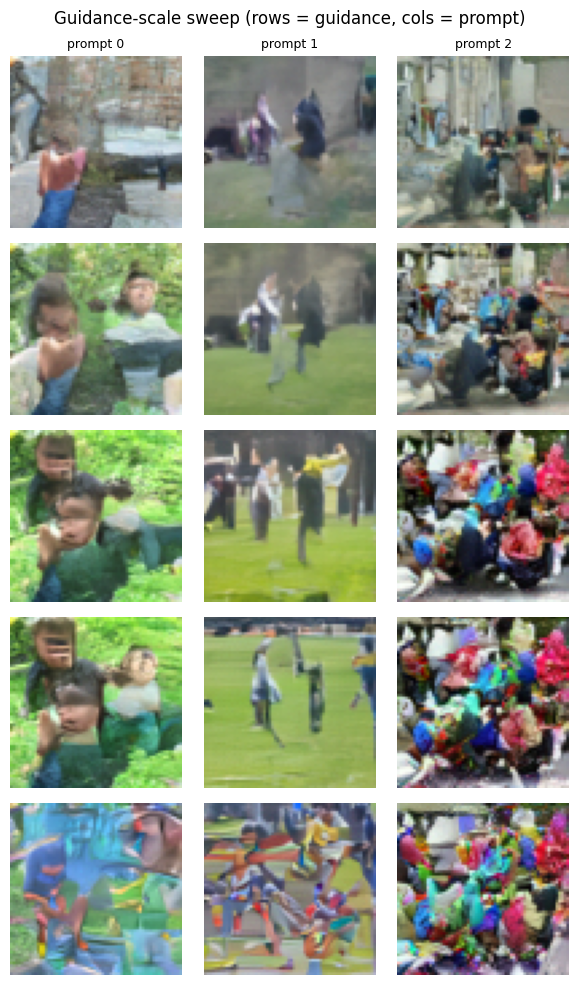

Saved guidance grid -> gallery/guidance/guidance_sweep.png


In [10]:
fig, axes = plt.subplots(len(GUIDANCE_SWEEP), SWEEP_PROMPTS,
                         figsize=(2.0 * SWEEP_PROMPTS, 2.0 * len(GUIDANCE_SWEEP)))
for r, g in enumerate(GUIDANCE_SWEEP):
    for c, im in enumerate(guid_grid[g]):
        axes[r, c].imshow(im); axes[r, c].axis('off')
    axes[r, 0].set_ylabel(f"s={g:g}", fontsize=10)
for c in range(SWEEP_PROMPTS):
    axes[0, c].set_title(f"prompt {sweep_idx[c]}", fontsize=9)
plt.suptitle("Guidance-scale sweep (rows = guidance, cols = prompt)")
plt.tight_layout()
plt.savefig(os.path.join(guid_dir, "guidance_sweep.png"), dpi=120, bbox_inches='tight')
plt.show()
print(f"Saved guidance grid -> {os.path.join(guid_dir, 'guidance_sweep.png')}")


In [11]:
# ---- CLIP-based objective metrics: text-image alignment + diversity ----
clip_model = CLIPModel.from_pretrained(CLIP_MODEL_NAME).to(DEVICE)
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_NAME)
clip_model.eval()

def clip_image_embedding(img):
    inputs = clip_processor(images=img.convert("RGB"), return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        e = clip_model.get_image_features(**inputs)
        if not isinstance(e, torch.Tensor):
            e = e.pooler_output
    return F.normalize(e, dim=-1)

def clip_text_embedding(text):
    inputs = clip_processor(text=text, return_tensors="pt", padding=True, truncation=True, max_length=77).to(DEVICE)
    with torch.no_grad():
        e = clip_model.get_text_features(**inputs)
        if not isinstance(e, torch.Tensor):
            e = e.pooler_output
    return F.normalize(e, dim=-1)

def alignment_score(img, text):
    return float((clip_image_embedding(img) * clip_text_embedding(text)).sum().item())

def diversity_score(images):
    feats = torch.stack([clip_image_embedding(im).cpu() for im in images])
    d, cnt = 0.0, 0
    for a in range(len(feats)):
        for b in range(a + 1, len(feats)):
            d += (feats[a] - feats[b]).norm().item(); cnt += 1
    return d / cnt if cnt else 0.0

rows = []
for g in GUIDANCE_SWEEP:
    al = [alignment_score(guid_grid[g][k], prompts_df.iloc[sweep_idx[k]]["caption"])
          for k in range(len(sweep_idx))]
    rows.append({
        "guidance": g,
        "mean_clip_align": round(float(np.mean(al)), 4),
        "diversity": round(diversity_score(guid_grid[g]), 4),
        "time_s_per_img": round(guid_time_per_img[g], 2),
    })
guid_metrics = pd.DataFrame(rows)
print("\nGuidance-scale metrics (higher align = better prompt match, higher diversity = more varied):")
print(guid_metrics.to_string(index=False))
guid_metrics.to_csv(os.path.join(guid_dir, "guidance_metrics.csv"), index=False)

del clip_model, clip_processor
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print(f"\nSaved guidance metrics -> {os.path.join(guid_dir, 'guidance_metrics.csv')}")



Guidance-scale metrics (higher align = better prompt match, higher diversity = more varied):
 guidance  mean_clip_align  diversity  time_s_per_img
      1.0           0.2105     0.6391            0.46
      3.0           0.2392     0.7024            0.47
      7.5           0.2394     0.7390            0.46
     10.0           0.2574     0.7531            0.47
     15.0           0.2126     0.6816            0.46

Saved guidance metrics -> gallery/guidance/guidance_metrics.csv


## Task 3 — Noise Schedule & Sampling Experiments

Vary three aspects of the reverse process, all on the same `3` prompts, to compare
quality vs. compute:

- **Sampling steps (DDIM)** — `25 / 50 / 100`: fewer steps = faster but less faithful denoising.
- **Noise schedule** — `linear / cosine` (linear vs cosine beta schedule).
- **Sampler** — `DDIM / DDPM`: DDIM (deterministic, few steps) vs DDPM (stochastic, all `T=1000`
  steps).

Each sub-sweep is saved to `gallery/sampling/`, with a side-by-side grid and per-setting timing.


steps=  25: 3 images in 0.7s (0.2s/img)
steps=  50: 3 images in 1.4s (0.5s/img)
steps= 100: 3 images in 2.8s (0.9s/img)


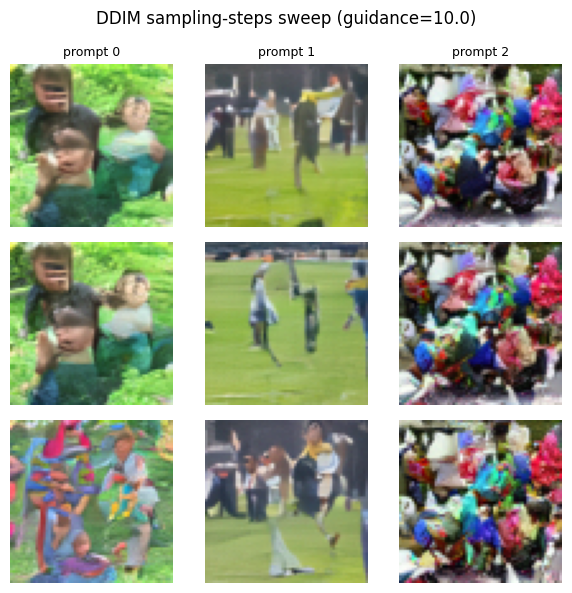

Saved steps grid -> gallery/sampling/steps_sweep.png


In [12]:
smp_dir = os.path.join(GALLERY_DIR, "sampling")
steps_grid = {}
steps_time = {}
for steps in STEPS_SWEEP:
    row = []
    t_total = 0.0
    for i in sweep_idx:
        img, t = generate_one(i, BASE_GUIDANCE, steps=steps, schedule="cosine",
                              sampler="ddim", seed=GLOBAL_SEED + i)
        t_total += t
        sub = os.path.join(smp_dir, f"steps_{steps}")
        os.makedirs(sub, exist_ok=True)
        img.save(os.path.join(sub, f"p{i:02d}.png"))
        row.append(img)
        manifest.append({"task": "steps", "index": i,
                         "prompt": prompts_df.iloc[i]["caption"], "seed": GLOBAL_SEED + i,
                         "guidance": BASE_GUIDANCE, "steps": steps, "schedule": "cosine",
                         "sampler": "ddim", "time_s": round(t, 2),
                         "file": f"sampling/steps_{steps}/p{i:02d}.png"})
    steps_grid[steps] = row
    steps_time[steps] = t_total / len(sweep_idx)
    print(f"steps={steps:4d}: {len(sweep_idx)} images in {t_total:.1f}s "
          f"({t_total/len(sweep_idx):.1f}s/img)")

fig, axes = plt.subplots(len(STEPS_SWEEP), SWEEP_PROMPTS,
                         figsize=(2.0 * SWEEP_PROMPTS, 2.0 * len(STEPS_SWEEP)))
for r, s in enumerate(STEPS_SWEEP):
    for c, im in enumerate(steps_grid[s]):
        axes[r, c].imshow(im); axes[r, c].axis('off')
    axes[r, 0].set_ylabel(f"{s} steps", fontsize=10)
for c in range(SWEEP_PROMPTS):
    axes[0, c].set_title(f"prompt {sweep_idx[c]}", fontsize=9)
plt.suptitle("DDIM sampling-steps sweep (guidance=%.1f)" % BASE_GUIDANCE)
plt.tight_layout()
plt.savefig(os.path.join(smp_dir, "steps_sweep.png"), dpi=120, bbox_inches='tight')
plt.show()
print(f"Saved steps grid -> {os.path.join(smp_dir, 'steps_sweep.png')}")


schedule=linear: 3 images in 1.4s (0.5s/img)
schedule=cosine: 3 images in 1.4s (0.5s/img)


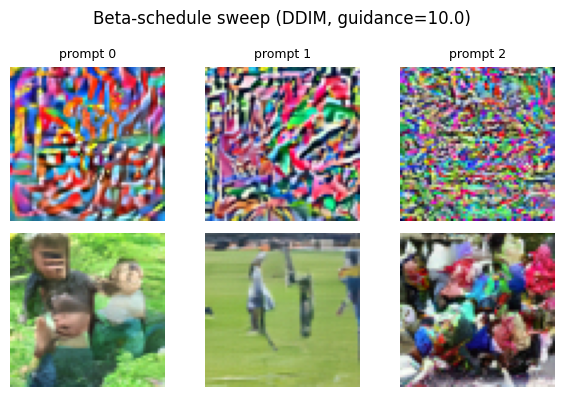

Saved schedule grid -> gallery/sampling/schedule_sweep.png


In [13]:
sched_grid, sched_time = {}, {}
for sched in SCHEDULE_SWEEP:
    row, t_total = [], 0.0
    for i in sweep_idx:
        img, t = generate_one(i, BASE_GUIDANCE, BASE_STEPS, schedule=sched,
                              sampler="ddim", seed=GLOBAL_SEED + i)
        t_total += t
        sub = os.path.join(smp_dir, f"sched_{sched}")
        os.makedirs(sub, exist_ok=True)
        img.save(os.path.join(sub, f"p{i:02d}.png"))
        row.append(img)
        manifest.append({"task": "schedule", "index": i,
                         "prompt": prompts_df.iloc[i]["caption"], "seed": GLOBAL_SEED + i,
                         "guidance": BASE_GUIDANCE, "steps": BASE_STEPS, "schedule": sched,
                         "sampler": "ddim", "time_s": round(t, 2),
                         "file": f"sampling/sched_{sched}/p{i:02d}.png"})
    sched_grid[sched] = row
    sched_time[sched] = t_total / len(sweep_idx)
    print(f"schedule={sched:6s}: {len(sweep_idx)} images in {t_total:.1f}s "
          f"({t_total/len(sweep_idx):.1f}s/img)")

fig, axes = plt.subplots(len(SCHEDULE_SWEEP), SWEEP_PROMPTS,
                         figsize=(2.0 * SWEEP_PROMPTS, 2.0 * len(SCHEDULE_SWEEP)))
for r, s in enumerate(SCHEDULE_SWEEP):
    for c, im in enumerate(sched_grid[s]):
        axes[r, c].imshow(im); axes[r, c].axis('off')
    axes[r, 0].set_ylabel(f"{s}", fontsize=10)
for c in range(SWEEP_PROMPTS):
    axes[0, c].set_title(f"prompt {sweep_idx[c]}", fontsize=9)
plt.suptitle("Beta-schedule sweep (DDIM, guidance=%.1f)" % BASE_GUIDANCE)
plt.tight_layout()
plt.savefig(os.path.join(smp_dir, "schedule_sweep.png"), dpi=120, bbox_inches='tight')
plt.show()
print(f"Saved schedule grid -> {os.path.join(smp_dir, 'schedule_sweep.png')}")


sampler=ddim: 3 images in 1.4s (0.5s/img)
sampler=ddpm: 3 images in 27.7s (9.2s/img)


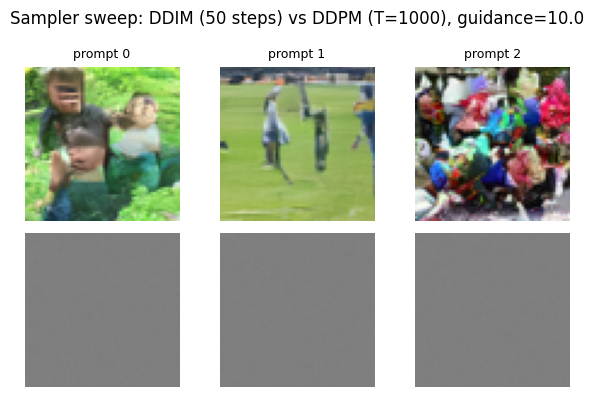

Saved sampler grid -> gallery/sampling/sampler_sweep.png


In [14]:
samp_grid, samp_time = {}, {}
for samp in SAMPLER_SWEEP:
    row, t_total = [], 0.0
    for i in sweep_idx:
        img, t = generate_one(i, BASE_GUIDANCE, BASE_STEPS, schedule="cosine",
                              sampler=samp, seed=GLOBAL_SEED + i)
        t_total += t
        sub = os.path.join(smp_dir, f"sampler_{samp}")
        os.makedirs(sub, exist_ok=True)
        img.save(os.path.join(sub, f"p{i:02d}.png"))
        row.append(img)
        manifest.append({"task": "sampler", "index": i,
                         "prompt": prompts_df.iloc[i]["caption"], "seed": GLOBAL_SEED + i,
                         "guidance": BASE_GUIDANCE,
                         "steps": BASE_STEPS if samp == "ddim" else N_TIMESTEPS,
                         "schedule": "cosine", "sampler": samp, "time_s": round(t, 2),
                         "file": f"sampling/sampler_{samp}/p{i:02d}.png"})
    samp_grid[samp] = row
    samp_time[samp] = t_total / len(sweep_idx)
    print(f"sampler={samp:4s}: {len(sweep_idx)} images in {t_total:.1f}s "
          f"({t_total/len(sweep_idx):.1f}s/img)")

fig, axes = plt.subplots(len(SAMPLER_SWEEP), SWEEP_PROMPTS,
                         figsize=(2.0 * SWEEP_PROMPTS, 2.0 * len(SAMPLER_SWEEP)))
for r, s in enumerate(SAMPLER_SWEEP):
    for c, im in enumerate(samp_grid[s]):
        axes[r, c].imshow(im); axes[r, c].axis('off')
    axes[r, 0].set_ylabel(f"{s.upper()}", fontsize=10)
for c in range(SWEEP_PROMPTS):
    axes[0, c].set_title(f"prompt {sweep_idx[c]}", fontsize=9)
plt.suptitle("Sampler sweep: DDIM (50 steps) vs DDPM (T=1000), guidance=%.1f" % BASE_GUIDANCE)
plt.tight_layout()
plt.savefig(os.path.join(smp_dir, "sampler_sweep.png"), dpi=120, bbox_inches='tight')
plt.show()
print(f"Saved sampler grid -> {os.path.join(smp_dir, 'sampler_sweep.png')}")


In [15]:
summary = {
    "model": f"TextConditionedUNet {n_params/1e6:.2f}M params (EMA weights)",
    "checkpoint": CHECKPOINT_PATH,
    "best_val_loss": round(float(ckpt["best_val_loss"]), 5),
    "resolution": f"{IMG_SIZE}x{IMG_SIZE}",
    "device": str(DEVICE),
    "n_baseline_prompts": len(prompts_df),
    "baseline_mean_s_per_img": round(float(np.mean(baseline_times)), 2),
    "guidance_metrics": guid_metrics.to_dict("records"),
    "steps_time_s_per_img": {str(k): round(v, 2) for k, v in steps_time.items()},
    "schedule_time_s_per_img": {k: round(v, 2) for k, v in sched_time.items()},
    "sampler_time_s_per_img": {k: round(v, 2) for k, v in samp_time.items()},
}
manifest_path = os.path.join(OUTPUT_DIR, "generation_manifest.json")
with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump({"summary": summary, "generations": manifest}, f, indent=2, ensure_ascii=False,
            default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print(f"Saved generation manifest -> {manifest_path}  ({len(manifest)} records)")

# ---- Qualitative memo (Markdown) ----
def _fmt_prompts():
    return "\n".join(f"  - **{i}** (id={prompts_df.iloc[i]['image_id']}): {prompts_df.iloc[i]['caption']}"
                      for i in range(len(prompts_df)))

memo = []
memo.append("# Milestone 2 — Conditional Generation & Parameter Sweeps (Memo)\n")
memo.append("**IE 7615 — Project 2**  |  David Fung  |  " + time.strftime("%Y-%m-%d") + "\n")
memo.append(f"Device: `{DEVICE}`  |  Model: `TextConditionedUNet` ({n_params/1e6:.1f}M params)  |  "
            f"Resolution: {IMG_SIZE}×{IMG_SIZE}  |  Schedule: `{BETA_SCHEDULE}`\n")
memo.append("\n---\n\n## 1. Setup\n")
memo.append(f"- Trained model: `{CHECKPOINT_PATH}` (best val loss **{ckpt['best_val_loss']:.4f}**).")
memo.append(f"- Text encoder: CLIP `{CLIP_MODEL_NAME}` (frozen, 512-dim) — same as Milestone 1.")
memo.append(f"- Baseline generation: **{len(prompts_df)}** curated prompts, guidance="
            f"**{BASE_GUIDANCE}**, {BASE_STEPS} DDIM steps, seed 42+i, cosine schedule.")
memo.append(f"- Sweeps: guidance {GUIDANCE_SWEEP}; steps {STEPS_SWEEP}; "
            f"schedule {SCHEDULE_SWEEP}; sampler {SAMPLER_SWEEP}.\n")
memo.append("### Baseline prompts (evenly spaced across the curated set)\n")
memo.append(_fmt_prompts() + "\n")

memo.append("\n## 2. Baseline gallery\n")
memo.append("Ground-truth (top) vs generated (bottom): "
            "`gallery/baseline/baseline_comparison.png`. Individual images: "
            "`gallery/baseline/base_XX.png`.\n")
memo.append(f"Baseline timing: **{summary['baseline_mean_s_per_img']}** s/image (mean).\n")

memo.append("\n## 3. Guidance-scale sweep\n")
memo.append("| Guidance `s` | Mean CLIP text–image align | Diversity | s/image |")
memo.append("|---|---|---|---|")
for _, r in guid_metrics.iterrows():
    memo.append(f"| {r['guidance']:g} | {r['mean_clip_align']} | {r['diversity']} | {r['time_s_per_img']} |")
memo.append("\nGrid: `gallery/guidance/guidance_sweep.png`.")
memo.append("\n**Observations** *(complete after reviewing the grid):*\n")
memo.append("- Low `s`: __ (e.g., weaker/blurry prompt alignment, more diverse) __")
memo.append("- High `s`: __ (e.g., sharper/saturated, lower diversity) __")
memo.append(f"- Best trade-off observed at `s` = __ (justify using the table above) __")

memo.append("\n## 4. Noise schedule & sampling\n")
memo.append("**Steps (DDIM):**")
memo.append("")
memo.append("| Steps | s/image |")
memo.append("|---|---|")
for k, v in steps_time.items():
    memo.append(f"| {k} | {v} |")
memo.append("\n**Schedule (DDIM, " + str(BASE_STEPS) + " steps):**\n")
memo.append("| Schedule | s/image |")
memo.append("|---|---|")
for k, v in sched_time.items():
    memo.append(f"| {k} | {v} |")
memo.append("\n**Sampler (guidance " + str(BASE_GUIDANCE) + "):**\n")
memo.append("| Sampler | s/image |")
memo.append("|---|---|")
for k, v in samp_time.items():
    memo.append(f"| {k.upper()} | {v} |")
memo.append("\nGrids: `steps_sweep.png`, `schedule_sweep.png`, `sampler_sweep.png`.")
memo.append("\n**Observations** *(complete after reviewing the grids):*\n")
memo.append("- Steps: __ (fidelity vs. speed) __")
memo.append("- Schedule: __ (linear vs cosine difference) __")
memo.append(f"- Sampler: __ (DDIM vs DDPM — DDPM runs all T={N_TIMESTEPS} steps; "
            f"~{max(samp_time.values()) / max(min(samp_time.values()), 1e-6):.0f}x slower) __")

memo.append("\n## 5. Conditioning check\n")
memo.append("To confirm the model is *conditional* (not just image-plausible), compare a "
            "prompt's output with the same seed using the unconditional (null) embedding "
            "(guidance≈0). They should differ and the guided one should match the text. "
            "Record the qualitative difference here.\n")

memo.append("\n## 6. Reproducibility\n")
memo.append(f"- Seeds: baseline 42+i; sweeps 42+i per prompt.")
memo.append(f"- Full parameter manifest: `outputs/generation_manifest.json` "
            f"({len(manifest)} generations, each with prompt, seed, guidance, steps, "
            "schedule, sampler, time, output path).")
memo.append("- Rerun: `Milestone_2/Integration_Training.ipynb` then "
            "`Milestone_2/Conditional_Generation.ipynb`.\n")

with open("conditional_generation_memo.md", "w", encoding="utf-8") as f:
    f.write("\n".join(memo))
print(f"\nSaved qualitative memo -> conditional_generation_memo.md")


Saved generation manifest -> outputs/generation_manifest.json  (52 records)

Saved qualitative memo -> conditional_generation_memo.md


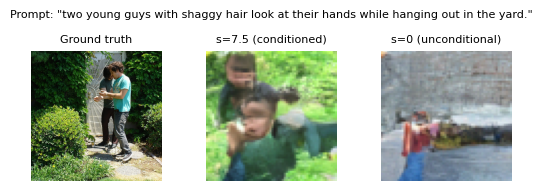

Saved conditioning check -> gallery/conditioning
s=7.5 should reflect the prompt; s=0 (same seed) should ignore it — confirming text conditioning, not just a plausible image.


In [16]:
# --- Prove conditioning: same seed, conditioned (s=7.5) vs unconditional (s=0) ---
i = 0
seed = GLOBAL_SEED + i
cond_img,   t1 = generate_one(i, guidance=7.5, steps=BASE_STEPS, schedule="cosine",
                              sampler="ddim", seed=seed)
uncond_img, t2 = generate_one(i, guidance=0.0, steps=BASE_STEPS, schedule="cosine",
                              sampler="ddim", seed=seed)   # eps = eps_uncond -> ignores text
cv_dir = os.path.join(GALLERY_DIR, "conditioning")
os.makedirs(cv_dir, exist_ok=True)
cond_img.save(os.path.join(cv_dir, "cond_i0.png"))
uncond_img.save(os.path.join(cv_dir, "uncond_i0.png"))
manifest.append({"task": "conditioning", "index": i,
                 "prompt": prompts_df.iloc[i]["caption"], "seed": seed,
                 "guidance": 7.5, "steps": BASE_STEPS, "schedule": "cosine",
                 "sampler": "ddim", "time_s": round(t1, 2), "file": "conditioning/cond_i0.png"})
manifest.append({"task": "conditioning", "index": i,
                 "prompt": prompts_df.iloc[i]["caption"], "seed": seed,
                 "guidance": 0.0, "steps": BASE_STEPS, "schedule": "cosine",
                 "sampler": "ddim", "time_s": round(t2, 2), "file": "conditioning/uncond_i0.png"})

fig, axes = plt.subplots(1, 3, figsize=(5.4, 1.9))
axes[0].imshow(gt_images[i]);    axes[0].axis('off'); axes[0].set_title("Ground truth", fontsize=8)
axes[1].imshow(cond_img);       axes[1].axis('off'); axes[1].set_title("s=7.5 (conditioned)", fontsize=8)
axes[2].imshow(uncond_img);     axes[2].axis('off'); axes[2].set_title("s=0 (unconditional)", fontsize=8)
plt.suptitle(f"Prompt: \"{prompts_df.iloc[i]['caption']}\"", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(cv_dir, "conditioning_check.png"), dpi=120, bbox_inches='tight')
plt.show()
print(f"Saved conditioning check -> {cv_dir}")
print("s=7.5 should reflect the prompt; s=0 (same seed) should ignore it — confirming "
      "text conditioning, not just a plausible image.")


In [17]:
del model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("Milestone 2 — Conditional Generation notebook complete.")
print("Deliverables: gallery/baseline/, gallery/guidance/, gallery/sampling/,")
print("              gallery/conditioning/, outputs/generation_manifest.json,")
print("              conditional_generation_memo.md")


Milestone 2 — Conditional Generation notebook complete.
Deliverables: gallery/baseline/, gallery/guidance/, gallery/sampling/,
              gallery/conditioning/, outputs/generation_manifest.json,
              conditional_generation_memo.md
